# Política de concessão de crédito

Pergunta do case: para quais clientes oferecer o empréstimo e qual o valor máximo para cada um?

## Sumário executivo

- **Proposta em uma frase:** o score diz quem é o cliente; a renda diz quanto cabe no orçamento.
- **Regra:** um score de perfil (0 a 1000) classifica o cliente nas faixas A a E. Faixas A, B e C são aprovadas. Faixas D e E são aprovadas com parcela limitada a **30% da renda**; se o pedido passar disso, o banco oferece um valor menor em vez de recusar.
- **Valor máximo:** valor presente da maior parcela permitida, na taxa e no prazo do pedido.
- **Impacto no período de teste (jan–jul/2021, que o modelo não viu):** a inadimplência dos contratos aprovados integralmente cai de **12,4% para 3,5%**, e o resultado econômico simplificado sobe de **2,3 para 5,3 milhões de reais**, podendo chegar a 6,65 milhões se as contrapropostas forem aceitas.
- **Robustez:** a conclusão se mantém com perda dado o default (LGD) de 40% a 80%.

O relatório segue a ordem: dados, alvo, variáveis, análise exploratória, score, política, impacto e riscos.

In [1]:
import sys, warnings
sys.path.append("..")            # permite importar os módulos de src/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display
from src import dados, features, scorecard as sc, politica as pol, graficos

pd.options.display.float_format = "{:,.3f}".format
SEMENTE = 42                      # semente fixa: resultados reproduzíveis

## 1. Dados e qualidade

Antes de modelar, confiro se as bases são o que o enunciado descreve: um empréstimo por cliente, datas válidas, valores plausíveis e categorias consistentes.

In [2]:
conc = dados.carregar_concessao()        # já corrige a escolaridade (espaço sobrando e nulos)
inad = dados.carregar_inadimplencia()

print(f"concessao:     {conc.shape[0]:,} linhas, {conc['id_cliente'].nunique():,} clientes únicos")
print(f"inadimplencia: {inad.shape[0]:,} linhas, {inad['id_cliente'].nunique():,} clientes")
dc, dr = conc["data_concessao"], inad["data_referencia"]
print(f"concessões de {dc.min():%d/%m/%Y} a {dc.max():%d/%m/%Y}")
print(f"referências de {dr.min():%d/%m/%Y} a {dr.max():%d/%m/%Y}")
print("nulos restantes:", int(conc.isna().sum().sum()))
conc.describe().T[["min", "50%", "max"]]

concessao:     30,000 linhas, 30,000 clientes únicos
inadimplencia: 257,960 linhas, 28,700 clientes
concessões de 20/08/2019 a 18/08/2022
referências de 30/09/2019 a 31/07/2022
nulos restantes: 0


,min,50%,max
id_cliente,1.000,"15,000.500","30,000.000"
data_concessao,2019-08-20 00:00:00,2021-02-12 00:00:00,2022-08-18 00:00:00
valor_emprestado,344.980,"9,219.040","190,806.750"
valor_parcela,120.540,"1,361.240","23,401.530"
valor_taxa,0.019,0.040,0.061
valor_prazo,3.000,9.000,15.000
valor_renda,"1,200.000","2,983.270","32,372.010"
valor_restritivos,0.000,21.610,"1,231.350"
flag_cliente_ativo,0.000,1.000,1.000
cod_agencia,1.000,70.000,99.000


In [3]:
# Escolaridade depois da limpeza: "Fundamental Incompleto" vinha duplicada por um espaço no fim,
# e 414 nulos viraram a categoria "Nulo" (ausência de informação também é informação)
display(conc["cat_escolaridade"].value_counts().to_frame("contratos"))

# Clientes sem nenhum registro de inadimplência: são os contratos mais recentes
sem_historico = conc[~conc["id_cliente"].isin(inad["id_cliente"])]
ds = sem_historico["data_concessao"]
print(f"{len(sem_historico):,} clientes sem histórico, "
      f"concedidos de {ds.min():%d/%m/%Y} a {ds.max():%d/%m/%Y}")

,contratos
cat_escolaridade,
Fundamental Incompleto,7768
Não Declarado,4965
Sem Escolaridade,4506
Fundamental Completo,3182
Médio Incompleto,2686
Médio Completo,2308
Superior Incompleto,1871
Superior Completo,1358
Pós-graduação,942


1,300 clientes sem histórico, concedidos de 01/07/2022 a 18/08/2022


**O que encontrei**

- 30.000 contratos e 30.000 clientes: um empréstimo por cliente, sem duplicidade.
- A escolaridade tinha uma categoria duplicada por espaço em branco e 414 valores nulos. Mantive os nulos como categoria própria, porque não declarar pode ser um sinal de risco.
- 1.300 clientes não têm nenhum registro de inadimplência: são concessões de julho e agosto de 2022, que ainda não tiveram nenhum fechamento de mês. Eles saem da modelagem.
- Renda, idade, taxa e prazo estão em faixas plausíveis.

## 2. Definição do alvo: quem é mau pagador?

O enunciado sugere usar o atraso 12 meses após a concessão. Antes de adotar, verifico nos dados se 12 meses é mesmo a janela certa, com a **curva de safra**: a porcentagem de contratos inadimplentes em cada mês de vida (MOB, *month on book*).

O denominador é sempre o total de contratos da coorte. Quem quita o empréstimo sai da base de inadimplência, então dividir só por quem continua na base inflaria a taxa.

mob,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
% inadimplentes,1.800,3.500,5.100,6.500,7.600,8.600,9.400,10.300,10.900,11.500,12.000,12.300,12.300,12.300,12.300


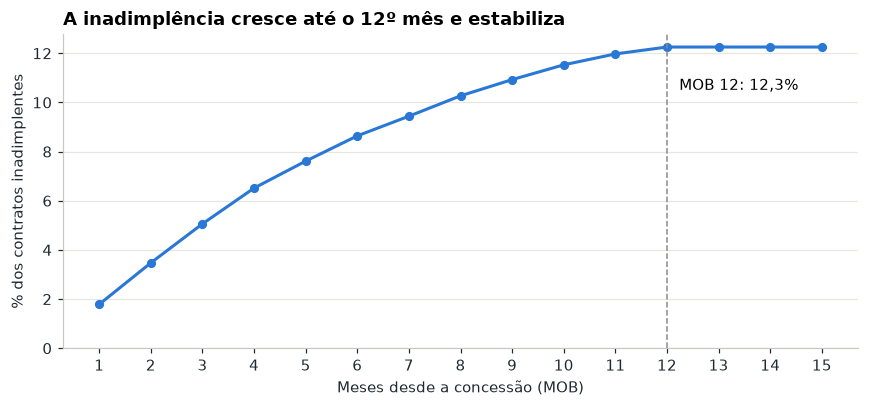

In [4]:
curva = dados.curva_de_safra(conc, inad, mob_max=15)   # só coortes com 15+ meses de observação
display((curva * 100).round(1).to_frame("% inadimplentes").T)
graficos.curva_safra(curva, nome="fig1_curva_safra");

In [5]:
# Alvo: mau = inadimplente no MOB 12. Sem registro no MOB 12 = quitou antes = bom.
# Só entram safras maduras: concedidas até 12 meses antes da extração (31/07/2021).
base = dados.construir_base_modelagem(conc, inad)
print(f"base madura: {len(base):,} contratos, {base['mau'].mean():.1%} de maus")

# A taxa de maus é estável entre as safras? (se não fosse, o teste fora do tempo seria injusto)
trimestre = base["data_concessao"].dt.to_period("Q")
safras = base.groupby(trimestre)["mau"].agg(contratos="size", taxa_maus="mean")
safras

base madura: 19,558 contratos, 12.3% de maus


,contratos,taxa_maus
data_concessao,,
2019Q3,1185,0.125
2019Q4,2508,0.127
2020Q1,2563,0.116
2020Q2,2421,0.120
2020Q3,2578,0.132
2020Q4,2520,0.117
2021Q1,2509,0.126
2021Q2,2438,0.121
2021Q3,836,0.127


**Conclusões**

- A inadimplência acumulada cresce até o 12º mês e estabiliza em 12,3%. Com 6 meses eu veria só 8,6% e subestimaria o risco em cerca de 30%.
- Contratos com menos de 12 meses de vida ficam fora: marcar como "bom" alguém que ainda pode atrasar deixaria o modelo otimista.
- A base madura tem **19.558 contratos e 12,3% de maus**: hoje, um em cada oito empréstimos está inadimplente depois de um ano.
- A taxa é estável entre os trimestres (11,6% a 13,2%), então não houve choque temporal na base.

## 3. Variáveis e separação treino x teste

Crio variáveis que fazem mais sentido de negócio do que as colunas brutas e separo os dados **no tempo**: o modelo aprende com o passado (até dez/2020) e é medido no período seguinte (jan–jul/2021), como aconteceria no uso real. Tudo o que é "aprendido" (faixas, pesos, cortes, tetos) vem só do treino.

In [6]:
base = features.criar_variaveis(base)
treino, teste = features.separar_treino_teste(base)     # corte em 31/12/2020

for nome, d in [("treino", treino), ("teste ", teste)]:
    print(f"{nome}: {len(d):,} contratos, {d['mau'].mean():.1%} de maus, "
          f"{d['data_concessao'].min():%m/%Y} a {d['data_concessao'].max():%m/%Y}")
novas = ["idade", "tempo_conta", "comprometimento", "restr_renda", "emp_renda"]
base[novas].describe().T[["min", "50%", "max"]]

treino: 13,775 contratos, 12.3% de maus, 08/2019 a 12/2020
teste : 5,783 contratos, 12.4% de maus, 01/2021 a 07/2021


,min,50%,max
idade,17.999,35.039,73.676
tempo_conta,2.661,19.974,132.884
comprometimento,0.100,0.499,0.900
restr_renda,0.000,0.006,0.522
emp_renda,0.278,3.158,10.447


| Variável | Fórmula | Por que faz sentido |
|---|---|---|
| `idade` | (concessão − nascimento) em anos | estabilidade de vida e de renda |
| `tempo_conta` | (concessão − abertura da conta) em meses | quanto o banco conhece o cliente |
| `comprometimento` | parcela ÷ renda | quanto da renda vai para a parcela |
| `restr_renda` | restritivos ÷ renda | dívida negativada em relação à renda |
| `emp_renda` | valor emprestado ÷ renda | tamanho do empréstimo em "salários" |

## 4. Análise exploratória orientada ao risco

Para cada variável calculo o **IV (Information Value)**, a medida usual em crédito do poder de separar bons e maus. Leitura: abaixo de 0,02 inútil; 0,02–0,1 fraco; 0,1–0,3 médio; 0,3–0,5 forte; acima de 0,5 merece conferência.

In [7]:
todas = features.VARS_PERFIL + features.VARS_EMPRESTIMO + features.VARS_DESCARTADAS
iv = sc.calcular_iv(treino, todas, categoricas=features.CATEGORICAS + ["cod_agencia"])
iv

,variavel,iv,leitura
0,cat_escolaridade,0.718,Muito forte (conferir)
1,comprometimento,0.453,Forte
2,valor_restritivos,0.339,Forte
3,restr_renda,0.298,Médio
4,flag_cliente_ativo,0.252,Médio
5,emp_renda,0.194,Médio
6,tempo_conta,0.158,Médio
7,valor_emprestado,0.087,Fraco
8,cod_agencia,0.074,Fraco
9,idade,0.071,Fraco


parcela até 30% da renda:      1.7% de maus (3,519 contratos)
parcela acima de 30% da renda: 15.9% de maus (10,256 contratos)


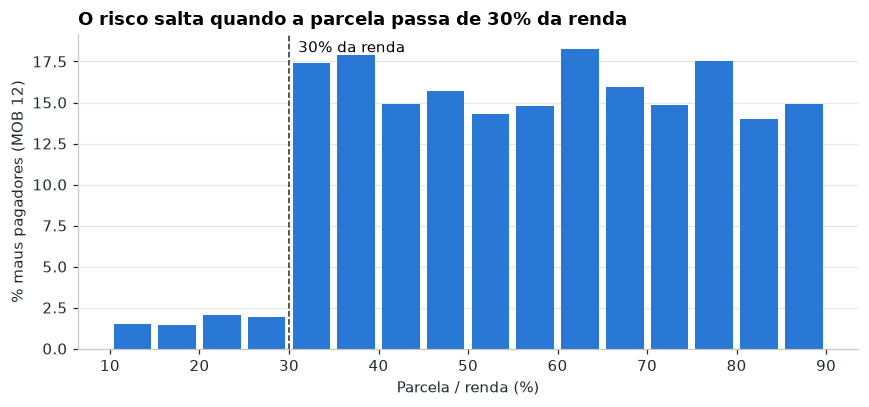

In [8]:
# O principal dado encontrado: a taxa de maus por comprometimento de renda tem um degrau em 30%
graficos.degrau_comprometimento(treino, nome="fig2_degrau_30");

ate_30 = treino["comprometimento"] <= 0.30
abaixo, acima = treino[ate_30], treino[~ate_30]
print(f"parcela até 30% da renda:      {abaixo['mau'].mean():.1%} de maus ({len(abaixo):,} contratos)")
print(f"parcela acima de 30% da renda: {acima['mau'].mean():.1%} de maus ({len(acima):,} contratos)")

In [9]:
# Taxa de maus por categoria e por faixa das principais variáveis de perfil
for var in ["cat_escolaridade", "flag_cliente_ativo"]:
    display(treino.groupby(var)["mau"].agg(contratos="size", taxa_maus="mean")
            .sort_values("taxa_maus", ascending=False))
for var in ["valor_restritivos", "tempo_conta", "idade", "valor_renda"]:
    ag = sc.Agrupador(var).fit(treino[var], treino["mau"])
    display(ag.tabela[["total", "taxa_maus"]].rename_axis(var))

,contratos,taxa_maus
cat_escolaridade,,
Não Declarado,2246,0.286
Nulo,178,0.242
Sem Escolaridade,2085,0.219
Médio Completo,1054,0.074
Fundamental Incompleto,3638,0.063
Médio Incompleto,1242,0.058
Fundamental Completo,1403,0.058
Superior Completo,665,0.057
Superior Incompleto,830,0.057


,contratos,taxa_maus
flag_cliente_ativo,,
0,2792,0.241
1,10983,0.093


,total,taxa_maus
valor_restritivos,,
"(-inf, 0.0]",5209,0.069
"(0.0, 42.554]",3056,0.076
"(42.554, 103.216]",2755,0.183
"(103.216, inf]",2755,0.216


,total,taxa_maus
tempo_conta,,
"(-inf, 13.108]",2763,0.195
"(13.108, 17.641]",2764,0.143
"(17.641, 22.602]",2752,0.114
"(22.602, 30.585]",2745,0.090
"(30.585, inf]",2751,0.072


,total,taxa_maus
idade,,
"(-inf, 26.807]",2755,0.175
"(26.807, 32.643]",2757,0.129
"(32.643, 37.652]",2753,0.117
"(37.652, 43.562]",2756,0.103
"(43.562, inf]",2754,0.089


,total,taxa_maus
valor_renda,,
"(-inf, 2557.806]",5510,0.130
"(2557.806, 5004.076]",5510,0.121
"(5004.076, inf]",2755,0.113


**Principais achados**

- **A renda sozinha não separa bons de maus (IV perto de zero). O que separa é quanto da renda vai para a parcela.** Até 30% da renda, 1,7% de maus; acima disso, 15,9%: nove vezes mais. Não é uma curva suave, é um degrau, e ele será a base da regra de valor máximo.
- Sinais fortes de perfil: restritivos acima de R\$ 40–50, relacionamento inativo (24% contra 9%), pouco tempo de conta e escolaridade "Não Declarado", "Sem Escolaridade" ou nula.
- A escolaridade tem IV muito alto, puxado por essas três categorias. É um ponto de atenção discutido na seção 8.
- **Variáveis deixadas de fora da decisão:** `valor_taxa` (é definida pelo próprio banco, usar seria circular, e não tem poder preditivo), `valor_renda` e `valor_prazo` (não separam) e `cod_agencia` (pode funcionar como proxy de região; fica só para monitoramento).

## 5. Score de perfil

A decisão de desenho mais importante: **separar "quem é o cliente" de "quanto emprestar"**. O score usa só variáveis do cliente (idade, tempo de conta, restritivos, restritivos ÷ renda, escolaridade e relacionamento ativo). O valor do empréstimo fica de fora, senão o valor máximo dependeria do score e o score dependeria do valor: uma regra circular.

Método: cada variável é dividida em faixas e convertida em **WoE** (*Weight of Evidence*), e uma regressão logística combina as variáveis. O resultado vira uma tabela de pontos que qualquer pessoa confere.

In [10]:
modelo = sc.Scorecard(features.VARS_PERFIL, features.CATEGORICAS).fit(treino)

# Todos os coeficientes devem ter o mesmo sinal: sinal trocado indicaria variáveis redundantes
display(modelo.coeficientes().round(3).to_frame())

for d in (treino, teste):
    d["score"] = modelo.score(d)

desempenho = pd.DataFrame({"treino": sc.metricas(treino["mau"], treino["score"]),
                        "teste fora do tempo": sc.metricas(teste["mau"], teste["score"])}).T
desempenho

,coeficiente
idade,-1.259
tempo_conta,-1.217
valor_restritivos,-0.939
restr_renda,-0.344
cat_escolaridade,-1.167
flag_cliente_ativo,-1.270


,auc,gini,ks
treino,0.839,0.678,0.516
teste fora do tempo,0.834,0.667,0.520


In [11]:
# A tabela de pontos é o modelo, o score do cliente é a soma dos pontos das faixas em que ele cai
pontos = modelo.tabela_de_pontos()
formato = {"taxa_maus": "{:.1%}", "woe": "{:+.2f}", "contratos": "{:,}"}
pontos.style.format(formato).hide(axis="index")

variavel,faixa,contratos,taxa_maus,woe,pontos
idade,"(-inf, 26.807]","2,755",17.5%,-0.42,50
idade,"(26.807, 32.643]","2,757",12.9%,-0.06,82
idade,"(32.643, 37.652]","2,753",11.7%,+0.05,93
idade,"(37.652, 43.562]","2,756",10.3%,+0.20,106
idade,"(43.562, inf]","2,754",8.9%,+0.36,120
tempo_conta,"(-inf, 13.108]","2,763",19.5%,-0.55,40
tempo_conta,"(13.108, 17.641]","2,764",14.3%,-0.18,72
tempo_conta,"(17.641, 22.602]","2,752",11.4%,+0.08,95
tempo_conta,"(22.602, 30.585]","2,745",9.0%,+0.35,119
tempo_conta,"(30.585, inf]","2,751",7.2%,+0.59,140


### Comparação com modelos desafiantes

Testo duas alternativas para saber quanto estou deixando na mesa: a mesma logística incluindo as variáveis do empréstimo, e um LightGBM com todas as variáveis.

In [12]:
from lightgbm import LGBMClassifier

# Desafiante 1: logística WoE também com variáveis do empréstimo
com_emprestimo = sc.Scorecard(features.VARS_PERFIL + ["comprometimento", "emp_renda"],
                              features.CATEGORICAS).fit(treino)

# Desafiante 2: LightGBM com todas as variáveis
numericas = ["idade", "tempo_conta", "valor_restritivos", "restr_renda", "flag_cliente_ativo",
             "comprometimento", "emp_renda", "valor_emprestado", "valor_prazo", "valor_renda",
             "valor_taxa"]
categorias = sorted(treino["cat_escolaridade"].unique())

def matriz_lgbm(d):
    X = d[numericas].copy()
    X["cat_escolaridade"] = pd.Categorical(d["cat_escolaridade"], categories=categorias)
    return X

lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=50,
                      subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                      random_state=SEMENTE, verbose=-1).fit(matriz_lgbm(treino), treino["mau"])

prob_treino = lgbm.predict_proba(matriz_lgbm(treino))[:, 1]
prob_teste = lgbm.predict_proba(matriz_lgbm(teste))[:, 1]

comparacao = pd.DataFrame({
    "Score de perfil (6 variáveis do cliente)": sc.metricas(teste["mau"], teste["score"]),
    "Logística + variáveis do empréstimo": sc.metricas(teste["mau"], com_emprestimo.score(teste)),
    "LightGBM com todas as variáveis": sc.metricas(teste["mau"], prob_teste, maior_e_pior=True),
}).T
auc_treino = sc.metricas(treino["mau"], prob_treino, maior_e_pior=True)["auc"]
print("AUC do LightGBM no treino:", auc_treino)
comparacao

AUC do LightGBM no treino: 0.927


,auc,gini,ks
Score de perfil (6 variáveis do cliente),0.834,0.667,0.520
Logística + variáveis do empréstimo,0.864,0.729,0.564
LightGBM com todas as variáveis,0.872,0.744,0.585


**Leitura**

- O score de perfil tem **AUC 0,834 e KS 0,52 no teste**, praticamente igual ao treino (0,839): não há sobreajuste.
- Incluir as variáveis do empréstimo leva a AUC a 0,864. Esse ganho não se perde: ele entra na política pela matriz de comprometimento (seção 6).
- O LightGBM chega a 0,872 no teste, só 0,008 acima da logística com as mesmas informações, e mostra sobreajuste (0,927 no treino). O ganho não compensa perder a tabela de pontos, que permite explicar cada decisão ao cliente e à auditoria.

### Faixas de risco A a E

Divido o score em cinco faixas pelos quintis do treino e aplico os mesmos cortes no teste. O **PSI** mede se a distribuição do score mudou entre os períodos (abaixo de 0,10 = estável).

cortes do score (E | D | C | B | A): [484 552 611 674]
PSI treino x teste: 0.002


,contratos (treino),maus (treino),maus (teste)
faixa,,,
A,2796,1.0%,0.9%
B,2738,2.3%,2.8%
C,2808,6.3%,6.3%
D,2691,13.7%,14.9%
E,2742,38.4%,37.1%


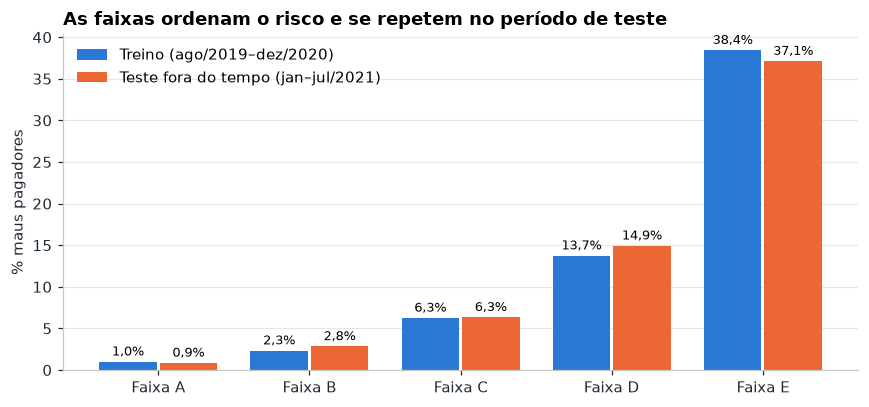

In [13]:
cortes = sc.cortes_das_faixas(treino["score"].values)
for d in (treino, teste):
    d["faixa"] = sc.atribuir_faixa(d["score"].values, cortes)

print("cortes do score (E | D | C | B | A):", cortes.astype(int))
print(f"PSI treino x teste: {sc.psi(treino['score'], teste['score'], cortes):.3f}")

resumo = pd.DataFrame({
    "contratos (treino)": treino.groupby("faixa", observed=False).size(),
    "maus (treino)": treino.groupby("faixa", observed=False)["mau"].mean(),
    "maus (teste)": teste.groupby("faixa", observed=False)["mau"].mean(),
}).reindex(pol.ORDEM_FAIXAS)
display(resumo.style.format({"maus (treino)": "{:.1%}", "maus (teste)": "{:.1%}"}))
graficos.maus_por_faixa(treino, teste, nome="fig3_faixas");

A taxa de maus vai de cerca de 1% na faixa A a 37% na faixa E, quase 40 vezes de diferença, e os valores se repetem no período de teste. O score ordena bem e é estável.

## 6. Política: cruzando perfil e capacidade de pagamento

Cruzo a faixa de risco com o comprometimento de renda. Primeiro a taxa de maus de cada combinação; depois traduzo em dinheiro.

In [14]:
maus = pol.matriz(treino, "maus")
display(maus.style.format("{:.1%}").background_gradient(cmap="Oranges", axis=None))

faixa_comp,≤20%,20-25%,25-30%,30-35%,35-40%,40-50%,>50%
faixa,,,,,,,
A,0.0%,0.0%,0.0%,0.6%,1.3%,1.2%,1.5%
B,0.3%,1.2%,0.0%,3.6%,3.8%,2.7%,2.8%
C,0.0%,1.1%,1.5%,8.1%,10.3%,7.9%,7.9%
D,0.8%,1.1%,1.6%,21.0%,24.6%,18.9%,16.8%
E,6.2%,6.4%,7.3%,54.4%,47.9%,47.8%,49.1%


O degrau dos 30% aparece em todas as faixas, mas o tamanho do salto depende do perfil: na faixa A quase nada muda; na faixa E a inadimplência vai de cerca de 6% para cerca de 50%. E um achado contraintuitivo: **a faixa E, com parcela até 30% da renda, tem só 6–7% de maus**, metade da média atual da carteira.

### Do risco ao resultado

Taxa de inadimplência não é a métrica final, resultado é. Para cada contrato:

- **Bom:** recebe todas as parcelas e devolve o valor captado com o custo do dinheiro: `parcela × prazo − valor × (1 + custo)^prazo`.
- **Mau:** perde `LGD × valor emprestado`.

**Premissas** (o case não informa, então ficam explícitas): custo de captação de 1% ao mês e LGD de 60%, com sensibilidade de 40% a 80% na seção 7. A fórmula é conservadora, pois assume que o mau pagador não pagou nenhuma parcela.

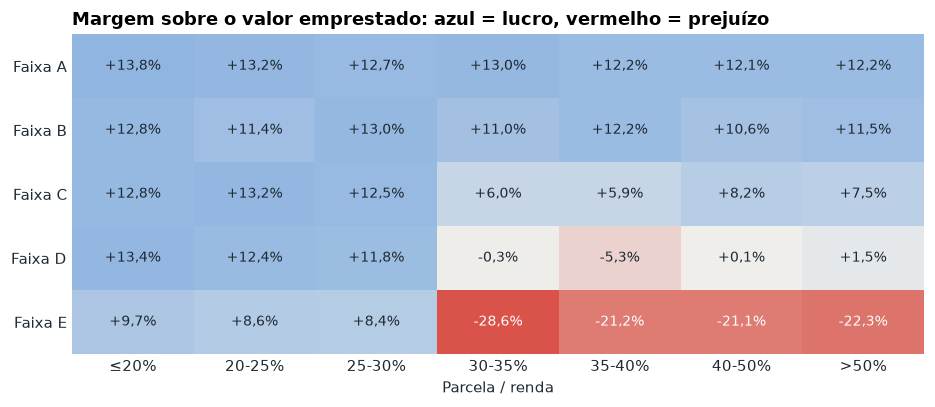

In [15]:
margem = pol.matriz(treino, "margem")       # resultado ÷ valor emprestado, em cada célula
graficos.mapa_margem(margem, nome="fig4_matriz_margem");

In [16]:
# A regra sai da matriz, faixa cujos contratos acima de 30% não entregam a margem mínima ganha teto
tetos = pol.derivar_tetos(treino, margem_minima=0.03)
print("teto de parcela ÷ renda por faixa:", tetos)

# Exemplo: cliente faixa D, renda R$ 4.000, taxa 4% a.m., 12 parcelas
exemplo = pol.valor_maximo(renda=4000, taxa=0.04, prazo=12, teto=0.30)
print(f"parcela máxima: R$ {4000 * 0.30:,.2f}  ->  valor máximo: R$ {exemplo:,.2f}")

teto de parcela ÷ renda por faixa: {'A': None, 'B': None, 'C': None, 'D': 0.3, 'E': 0.3}
parcela máxima: R$ 1,200.00  ->  valor máximo: R$ 11,262.09


### A regra proposta

| Faixa | Decisão | Teto de parcela ÷ renda | Racional |
|---|---|---|---|
| A, B | Aprova | sem teto observado nos dados | lucrativas em todo o intervalo |
| C | Aprova | sem teto observado nos dados | margem cai acima de 30%, mas segue positiva |
| D | Aprova com teto | 30% | acima de 30% a margem fica perto de zero ou negativa |
| E | Aprova com teto | 30% | acima de 30% perde mais de 20% do valor; abaixo, lucra |

**Valor máximo** = valor presente da maior parcela permitida:
`valor_max = renda × teto × [1 − (1 + taxa)^(−prazo)] ÷ taxa`

**Fluxo de decisão:** o cliente pede um valor em n parcelas → calcula-se o score e a faixa → calcula-se o comprometimento do pedido → se couber no teto da faixa, aprova; se não, o banco faz uma **contraproposta** com o valor máximo (ou prazo maior).

**Opção para o comitê (teto prudencial):** os dados não mostram risco extra para A, B e C mesmo com comprometimento alto, mas comprometer 80–90% da renda é pouco realista e expõe o banco à Lei do Superendividamento. Um teto de 50% para essas faixas é avaliado na próxima seção, com o custo.

## 7. Impacto: política atual x proposta

Aplico a regra no período de teste. Separo o que é **medido** (contratos que seriam aprovados integralmente, com o desfecho que realmente aconteceu) do que é **estimado** (contratos que receberiam contraproposta: suponho que o cliente aceita o valor menor e passa a ter o risco da sua faixa dentro do teto).

In [17]:
tabela = []
for lgd in (0.40, 0.60, 0.80):                      # sensibilidade à premissa de perda
    r = pol.simular_impacto(teste, treino, tetos, lgd=lgd)
    tabela.append({
        "LGD": f"{lgd:.0%}",
        "atual (R$ mi)": r["atual_resultado"] / 1e6,
        "proposta medida (R$ mi)": r["proposta_resultado_medido"] / 1e6,
        "com contraproposta (R$ mi)": r["proposta_resultado_com_contraproposta"] / 1e6,
    })

r = pol.simular_impacto(teste, treino, tetos)        # cenário base, LGD 60%
print(f"teste: {r['contratos']:,} contratos, R$ {r['valor_pedido'] / 1e6:.1f} mi emprestados")
print(f"política atual: 100% aprovados, {r['atual_maus']:.1%} de maus")
print(f"proposta: {r['aprovados_integral']:.1%} aprovados integralmente, "
      f"{r['proposta_maus']:.1%} de maus")
print(f"contrapropostas: {r['contratos_reduzidos']:,} contratos, "
      f"em média {r['valor_reduzido_medio']:.0%} do valor pedido")
pd.DataFrame(tabela).set_index("LGD").round(2)

teste: 5,783 contratos, R$ 77.2 mi emprestados
política atual: 100% aprovados, 12.4% de maus
proposta: 71.3% aprovados integralmente, 3.5% de maus
contrapropostas: 1,661 contratos, em média 55% do valor pedido


,atual (R$ mi),proposta medida (R$ mi),com contraproposta (R$ mi)
LGD,,,
40%,4.430,5.750,7.150
60%,2.260,5.350,6.650
80%,0.100,4.950,6.140


In [18]:
# Variante prudente, teto de 50% também para A, B e C
tetos_prudentes = {**tetos, "A": 0.50, "B": 0.50, "C": 0.50}
p = pol.simular_impacto(teste, treino, tetos_prudentes)
print(f"variante prudente: {p['aprovados_integral']:.1%} aprovados integralmente, "
      f"{p['contratos_reduzidos']:,} contrapropostas, "
      f"resultado com contraproposta R$ {p['proposta_resultado_com_contraproposta'] / 1e6:.2f} mi")

variante prudente: 40.3% aprovados integralmente, 3,453 contrapropostas, resultado com contraproposta R$ 5.98 mi


**Leitura**

- A proposta aprova integralmente 71% dos contratos, com **3,5% de maus contra 12,4% hoje**. Ninguém é recusado: os demais recebem um valor menor.
- O resultado medido sobe de **R\$ 2,26 mi para R\$ 5,35 mi** (2,4 vezes), usando só contratos que realmente aconteceram. Com as contrapropostas aceitas, o potencial é de R\$ 6,65 mi.
- **A regra é robusta à premissa de perda:** com LGD de 80%, a política atual quase zera o resultado (R\$ 0,10 mi) e a proposta mantém R\$ 4,95 mi.
- O teto prudencial de 50% para A, B e C custa cerca de 10% do resultado potencial (R\$ 5,98 mi), e depende mais das contrapropostas.

O "resultado" é simplificado: não inclui custos operacionais, impostos, provisão nem capital regulatório. Serve para **comparar políticas**, não como projeção de lucro contábil.

## 8. Riscos, LGPD e próximos passos

### Uso ético das variáveis

Gênero, raça e religião não existem na base. Escolaridade e idade merecem atenção, então meço o custo de retirá-las.

In [19]:
def auc_teste(variaveis):
    m = sc.Scorecard(variaveis, features.CATEGORICAS).fit(treino)
    return sc.metricas(teste["mau"], m.score(teste))

perfil = features.VARS_PERFIL
pd.DataFrame({
    "score completo": auc_teste(perfil),
    "sem idade": auc_teste([v for v in perfil if v != "idade"]),
    "sem escolaridade": auc_teste([v for v in perfil if v != "cat_escolaridade"]),
    "sem idade e sem escolaridade": auc_teste(
        [v for v in perfil if v not in ("idade", "cat_escolaridade")]),
}).T

,auc,gini,ks
score completo,0.834,0.667,0.520
sem idade,0.823,0.647,0.497
sem escolaridade,0.774,0.549,0.416
sem idade e sem escolaridade,0.759,0.518,0.390


- **Escolaridade** não é dado sensível pela LGPD, mas pode ser questionada. Sem ela, a AUC cai de 0,834 para 0,774. O sinal vem principalmente de "Não Declarado" e "Sem Escolaridade", ou seja, em boa parte de um comportamento cadastral. Proposta: manter, monitorar e melhorar a qualidade do cadastro; a decisão final é do comitê, que agora conhece o custo.
- **Idade:** no modelo, mais idade significa menos risco, então a política não penaliza idosos. Retirá-la custa pouco (AUC 0,823).
- **Explicabilidade:** o score é uma tabela de pontos, o que atende ao direito de revisão de decisões automatizadas (LGPD, art. 20).

### Limitações

- **Viés de seleção:** a base só tem quem foi aprovado no passado. Por isso a proposta só aprova perfis que o banco já aprovou.
- **Contraproposta é hipótese:** o efeito de reduzir o valor não foi observado nos dados e precisa de piloto.
- **Premissas financeiras** (LGD e custo de captação) não vêm da base; por isso a análise de sensibilidade.
- **Dados fictícios:** o degrau em 30% é muito nítido; em dados reais a curva tende a ser mais suave.
- As safras de ago/2021 em diante ficam fora por não terem 12 meses de observação.

### Plano de implantação e monitoramento

- **Piloto:** 10–20% dos pedidos seguem a nova política por 3 a 6 meses; o restante segue a atual.
- **Indicador antecipado:** inadimplência no MOB 3 e no MOB 6 por faixa, já que o alvo leva 12 meses para maturar.
- **PSI mensal do score:** abaixo de 0,10 estável; 0,10–0,25 atenção; acima de 0,25 recalibrar.
- **Revisão anual** do modelo e dos tetos pelo comitê de crédito.

In [20]:
# Base para o Power BI, um contrato por linha, com score, faixa e decisão da política
bi = pd.concat([treino.assign(conjunto="Treino"), teste.assign(conjunto="Teste")])
bi = pol.aplicar_politica(bi, tetos)
bi["faixa_comp"] = pol.faixa_comprometimento(bi["comprometimento"])
bi["resultado"] = pol.resultado_contrato(bi["valor_emprestado"], bi["valor_parcela"],
                                        bi["valor_prazo"], bi["mau"])
bi["safra"] = bi["data_concessao"].dt.to_period("M").dt.to_timestamp()

colunas = ["id_cliente", "data_concessao", "safra", "conjunto", "score", "faixa",
        "comprometimento", "faixa_comp", "valor_renda", "valor_emprestado",
        "valor_parcela", "valor_prazo", "valor_taxa", "cat_escolaridade",
        "flag_cliente_ativo", "cod_agencia", "mau", "decisao", "valor_aprovado",
        "resultado"]
bi[colunas].to_csv("../data/base_powerbi.csv", index=False, sep=";", decimal=",",
                encoding="utf-8-sig")